# Cosmetics preprocessing  — ingredient + skin-type to exploratory percentage score

**Input X:** ingredient presence (training vocabulary) + selected skin type (one-hot).

**Target y:** a **continuous 0–100 exploratory statistical affinity score** computed from ingredient–skin-tag associations in the original dataset. **It is NOT measured compatibility, safety, clinical suitability, or a validated probability.** The source contains only binary skin-type tags, not real percentages. Scores are derived from training annotations; their quality cannot be independently validated using this dataset.

Train a **regression** model only as a prototype to reproduce this heuristic. The score for train products uses out-of-fold statistics; validation/test use statistics fitted on the training split only. The five skin types are features, not classification targets. Products with all-zero tags are excluded because their labels are ambiguous.

### Data Loading and Preprocessing

*note: make sure the cosmetics.csv file is found in the same folder/path as this notebook.

Dataset link: https://www.kaggle.com/datasets/kingabzpro/cosmetics-datasets

#### Import Libraries and Set Variables

In [35]:
from pathlib import Path
import json, re, sys, platform
import numpy as np
import pandas as pd
import sklearn, scipy
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GroupShuffleSplit
import joblib
import matplotlib.pyplot as plt # added for EDA
from collections import Counter # added for EDA
import seaborn as sns # added for EDA


RAW_CSV = Path("cosmetics.csv")
OUT_DIR = Path("prepared")
SEED = 42
TEST_FRACTION = 0.15
VALIDATION_FRACTION = 0.15
MIN_INGREDIENTS = 3
MIN_DF = 3
SKIN = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]
REQUIRED = ["Label", "Brand", "Name", "Price", "Rank", "Ingredients", *SKIN]
# Keep only the verified spelling aliases. No fuzzy matching of chemical names.
ALIASES = {"aqua": "water", "eau": "water", "parfum": "fragrance",
           "frgrance": "fragrance", "carmbomer": "carbomer",
           "ethlhexylglycerin": "ethylhexylglycerin",
           "phenoxythanol": "phenoxyethanol", "pan-thenol": "panthenol"}
# Do NOT conflate vitamin C with a particular derivative, or different PEG/polyquaternium grades.


#### Preprocessing
standardizing text, removing invalid rows containing nan, removing extra whitespace, filtering out brands with less than 3 ingredients etc..

In [2]:
def parse_ingredients(value):
    """Conservative, deterministic comma-delimited parsing; keep meaningful parentheses."""
    if pd.isna(value):
        return []
    text = str(value).lower().replace("\n", ",").replace(";", ",")
    result, seen = [], set()
    for part in text.split(","):
        part = re.sub(r"[*†‡•]", "", part)
        part = re.sub(r"\s+", " ", part).strip(" .:-")
        if part in {"", "#name?", "nan", "none", "n/a"} or not re.search(r"[a-z]", part):
            continue
        # Parentheses can be part of INCI names; do not erase their content.
        part = ALIASES.get(part, part)
        if part not in seen:
            seen.add(part)
            result.append(part)
    return result

def check_input(frame):
    missing = sorted(set(REQUIRED) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing source columns: {missing}. Supply the original CSV with headers.")
    if frame.empty:
        raise ValueError("Source CSV is empty")
    for col in SKIN:
        values = pd.to_numeric(frame[col], errors="coerce")
        if values.isna().any() or not values.isin([0, 1]).all():
            raise ValueError(f"{col} must contain only 0/1, without missing values")
        frame[col] = values.astype("int8")
    return frame

if not RAW_CSV.exists():
    raise FileNotFoundError(f"Missing {RAW_CSV}. Download the ORIGINAL cosmetics.csv from Kaggle.")
df = check_input(pd.read_csv(RAW_CSV))
raw_count = len(df)
df = df.copy()
df["source_row"] = np.arange(len(df))
df["brand_key"] = df["Brand"].fillna("").astype(str).str.strip().str.casefold()
df["name_key"] = df["Name"].fillna("").astype(str).str.strip().str.casefold()
df = df.loc[df["brand_key"].ne("") & df["name_key"].ne("")].copy()
# Conflicting annotations for the same product are not silently combined.
conflicts = df.groupby(["brand_key", "name_key"])[SKIN].nunique().gt(1).any(axis=1)
if conflicts.any():
    print(f"WARNING: {int(conflicts.sum())} duplicate product keys have conflicting skin tags; first row retained")
df = df.drop_duplicates(["brand_key", "name_key"], keep="first").copy()
df["tokens"] = df["Ingredients"].map(parse_ingredients)
df["n_ing"] = df["tokens"].map(len)
df = df.loc[df["n_ing"] >= MIN_INGREDIENTS].copy().reset_index(drop=True)
df["Ingredients_clean"] = df["tokens"].map(lambda t: ", ".join(t))
df["has_skin_label"] = df[SKIN].sum(axis=1).gt(0)
df["Rank_clean"] = pd.to_numeric(df["Rank"], errors="coerce")
df.loc[df["Rank_clean"] <= 0, "Rank_clean"] = np.nan
# Rows with all-zero labels are unknown, NOT confirmed negatives: exclude from supervised splits.
labeled = df.loc[df["has_skin_label"]].copy().reset_index(drop=True)
if len(labeled) < 20:
    raise ValueError("Not enough labeled products for reliable train/validation/test splitting")
# Group identical ingredient sets so the same formulation cannot cross splits.
labeled["formulation_group"] = labeled["tokens"].map(lambda t: "|".join(sorted(set(t))))
print(f"Raw={raw_count}, cleaned={len(df)}, labeled={len(labeled)}, unknown/all-zero={len(df)-len(labeled)}")


Raw=1472, cleaned=1266, labeled=890, unknown/all-zero=376


#### Exploratory Data Analysis (EDA)
EDA inspired and taken from: https://www.geeksforgeeks.org/data-analysis/exploratory-data-analysis-in-python/

In [3]:
# df contains the filtered and cleaned data
df.head()

,Label,Brand,Name,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,source_row,brand_key,name_key,tokens,n_ing,Ingredients_clean,has_skin_label,Rank_clean
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1,0,la mer,crème de la mer,"[algae (seaweed) extract, mineral oil, petrola...",42,"algae (seaweed) extract, mineral oil, petrolat...",True,4.1
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1,1,sk-ii,facial treatment essence,"[galactomyces ferment filtrate (pitera), butyl...",7,"galactomyces ferment filtrate (pitera), butyle...",True,4.1
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0,2,drunk elephant,protini™ polypeptide cream,"[water, dicaprylyl carbonate, glycerin, cetear...",58,"water, dicaprylyl carbonate, glycerin, ceteary...",True,4.4
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1,3,la mer,the moisturizing soft cream,"[algae (seaweed) extract, cyclopentasiloxane, ...",78,"algae (seaweed) extract, cyclopentasiloxane, p...",True,3.8
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1,4,it cosmetics,your skin but better™ cc+™ cream with spf 50+,"[water, snail secretion filtrate, phenyl trime...",82,"water, snail secretion filtrate, phenyl trimet...",True,4.1


In [4]:
# the cleaned data has 1266 rows and 19 columns
df.shape

(1266, 19)

In [5]:
# list all the columns with their type

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1266 entries, 0 to 1265
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Label              1266 non-null   object 
 1   Brand              1266 non-null   object 
 2   Name               1266 non-null   object 
 3   Price              1266 non-null   int64  
 4   Rank               1266 non-null   float64
 5   Ingredients        1266 non-null   object 
 6   Combination        1266 non-null   int8   
 7   Dry                1266 non-null   int8   
 8   Normal             1266 non-null   int8   
 9   Oily               1266 non-null   int8   
 10  Sensitive          1266 non-null   int8   
 11  source_row         1266 non-null   int64  
 12  brand_key          1266 non-null   object 
 13  name_key           1266 non-null   object 
 14  tokens             1266 non-null   object 
 15  n_ing              1266 non-null   int64  
 16  Ingredients_clean  1266 

Important observations: combination, dry, normal,
oily, and sensitive are integers.

New columns were added from the preprocessing (ex: number of ingredients n_ing was added)

tokens and Ingredients_clean columns store the preprocessed
ingredients, but in different data structures.
Tokens column has a python list of strings while Ingredients_clean stores ingredients in one string.

In [6]:
# summary statistics of each column
# the average price of a cosmetic product is 55$
# users on average give a rating of 4 for the products (from rank column)

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,1266.0,55.646130,45.577693,3.0,30.00,42.0,65.75,370.0
Rank,1266.0,4.152765,0.621992,0.0,4.00,4.3,4.50,5.0
Combination,1266.0,0.682464,0.465702,0.0,0.00,1.0,1.00,1.0
Dry,1266.0,0.635071,0.481600,0.0,0.00,1.0,1.00,1.0
Normal,1266.0,0.675355,0.468427,0.0,0.00,1.0,1.00,1.0
Oily,1266.0,0.629542,0.483118,0.0,0.00,1.0,1.00,1.0
Sensitive,1266.0,0.533175,0.499095,0.0,0.00,1.0,1.00,1.0
source_row,1266.0,736.897314,424.038078,0.0,371.25,741.5,1098.75,1470.0
n_ing,1266.0,35.251975,18.028844,3.0,23.00,33.0,44.00,147.0
Rank_clean,1250.0,4.205920,0.409980,1.0,4.00,4.3,4.50,5.0


In [7]:
# double check if there are still
# any missing values after preprocessing

df.isnull().sum()

,0
Label,0
Brand,0
Name,0
Price,0
Rank,0
Ingredients,0
Combination,0
Dry,0
Normal,0
Oily,0


Only rank_clean column has null value.

rank_clean is the cleaned rank column from the preprocessing.

It might not be used as a feature in all cases.

Water is the most common ingredient across all cosmetic products

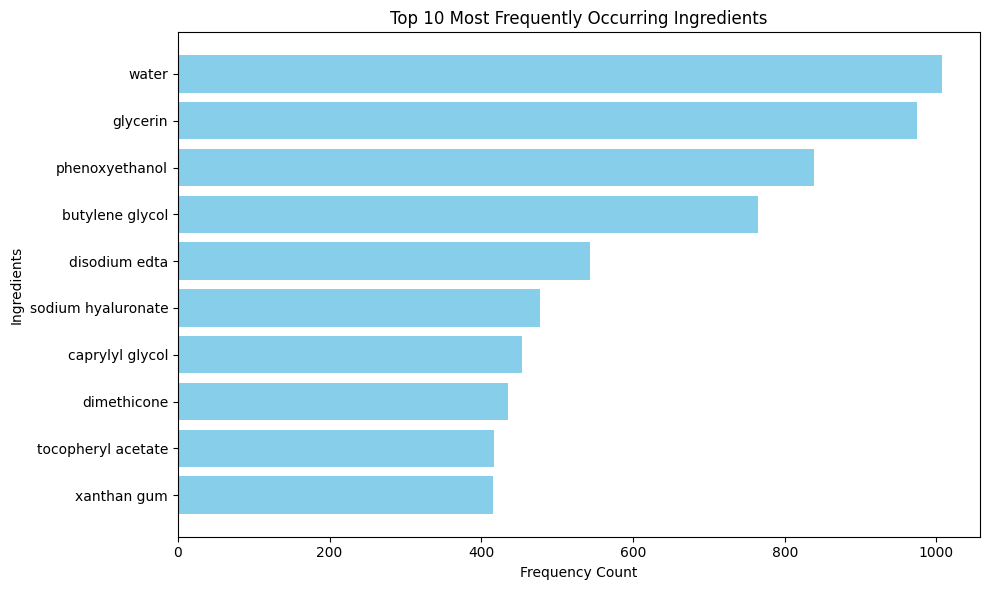

In [34]:
# Univariate Analysis
# AI-generated code

from collections import Counter

# Flatten all individual ingredient tokens across all products
all_ingredients = [ingredient for tokens_list in df["tokens"] for ingredient in tokens_list]

# Count the frequency of each ingredient
ingredient_frequencies = Counter(all_ingredients)

# Select the top 10 most common ingredients to visualize
top_n = 10
most_common_ingredients = ingredient_frequencies.most_common(top_n)

# Separate ingredient names and their respective counts
ingredients, counts = zip(*most_common_ingredients)

# Create a horizontal bar plot for readability
plt.figure(figsize=(10, 6))
plt.barh(ingredients[::-1], counts[::-1], color='skyblue')
plt.title(f"Top {top_n} Most Frequently Occurring Ingredients")
plt.xlabel("Frequency Count")
plt.ylabel("Ingredients")
plt.tight_layout()
plt.show()

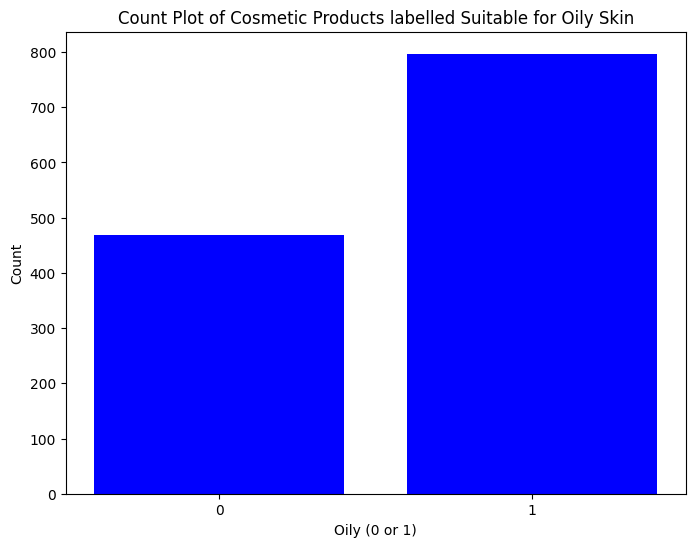

In [33]:
#Univariate Analysis

# pick a skintype to display using the skintype variable
skintype = 'Oily'
skintype_counts = df[skintype].value_counts()

plt.figure(figsize=(8, 6))
plt.bar(skintype_counts.index, skintype_counts, color='blue')
plt.title(f'Count Plot of Cosmetic Products labelled Suitable for {skintype} Skin')
plt.xlabel(f'{skintype} (0 or 1)')
plt.ylabel('Count')
plt.xticks([0, 1])  # Ensure x-axis has clean, non-decimal ticks
plt.show()

There is almost a balanced distribution of cosmetic products labelled suitable for sensitive skin.
The dry-skin labelling of products is imbalanced; more products are labelled for dry skin than those without the dry-skin label. The Combination-skin labelling is also imbalanced with more products labelled suitable for Combination skin. The same observations were found for the Normal-skin labelling and Oily-Skin labelling.

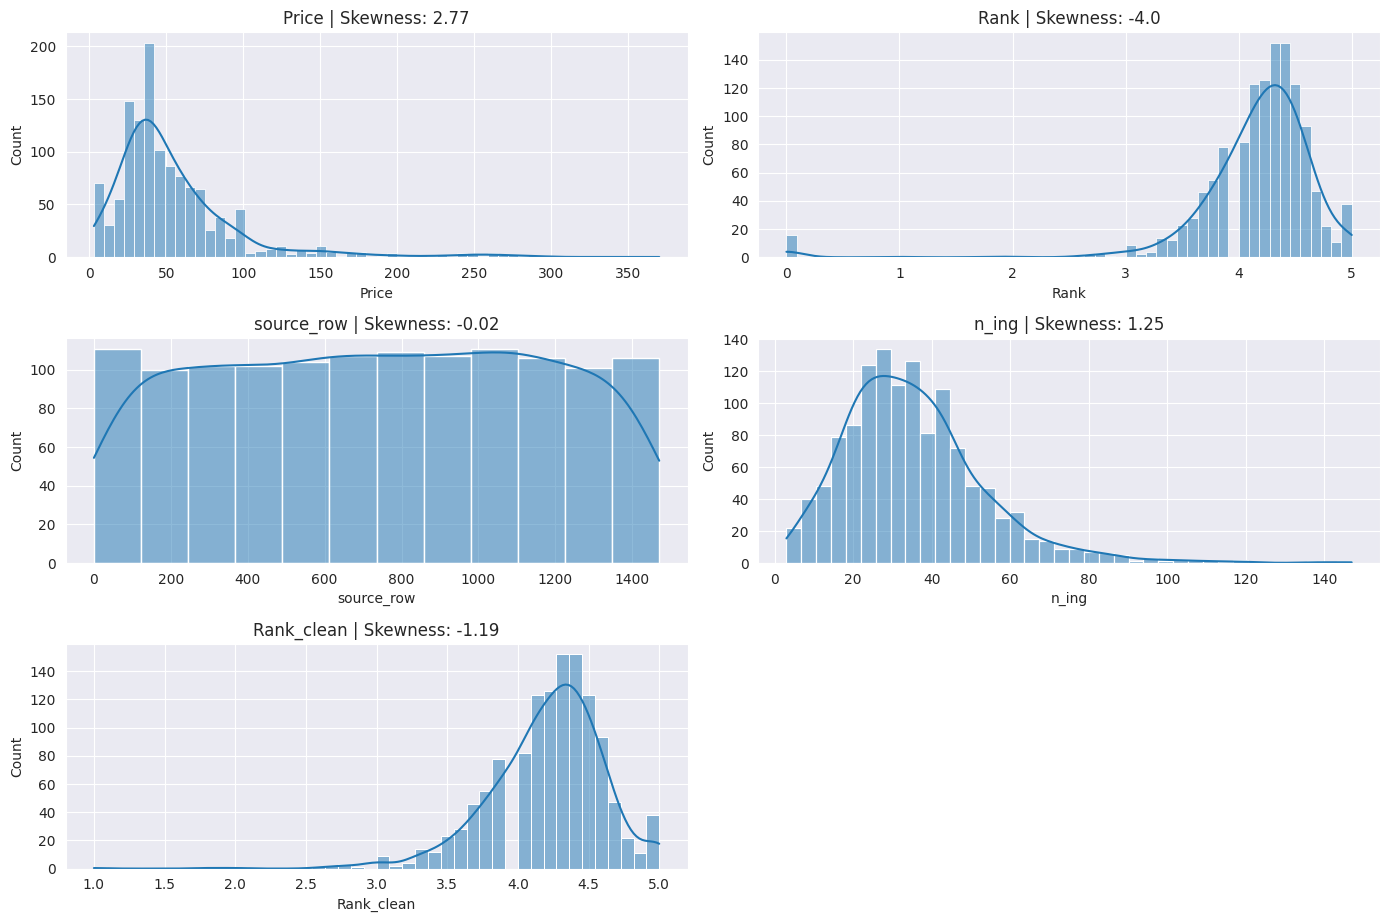

In [36]:
#Univariate Analysis

# Kernel density plots to visualize the data distribution

sns.set_style("darkgrid")

# select only numeric data

numerical_columns = df.select_dtypes(include=["int8","int64", "float64"]).columns

plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 2, idx)
    sns.histplot(df[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")

plt.tight_layout()
plt.show()

source_row is an index tracking column added during the preprocessing step. It stored the original row index of each product before any rows were filtered (it most probably won't be used for machine learning).

Price is skewed to the right (stretched to the right with a positive skewness). n_ing also has a positive skewness.

Rank_clean is skewed to the left (with a negative skewness value)

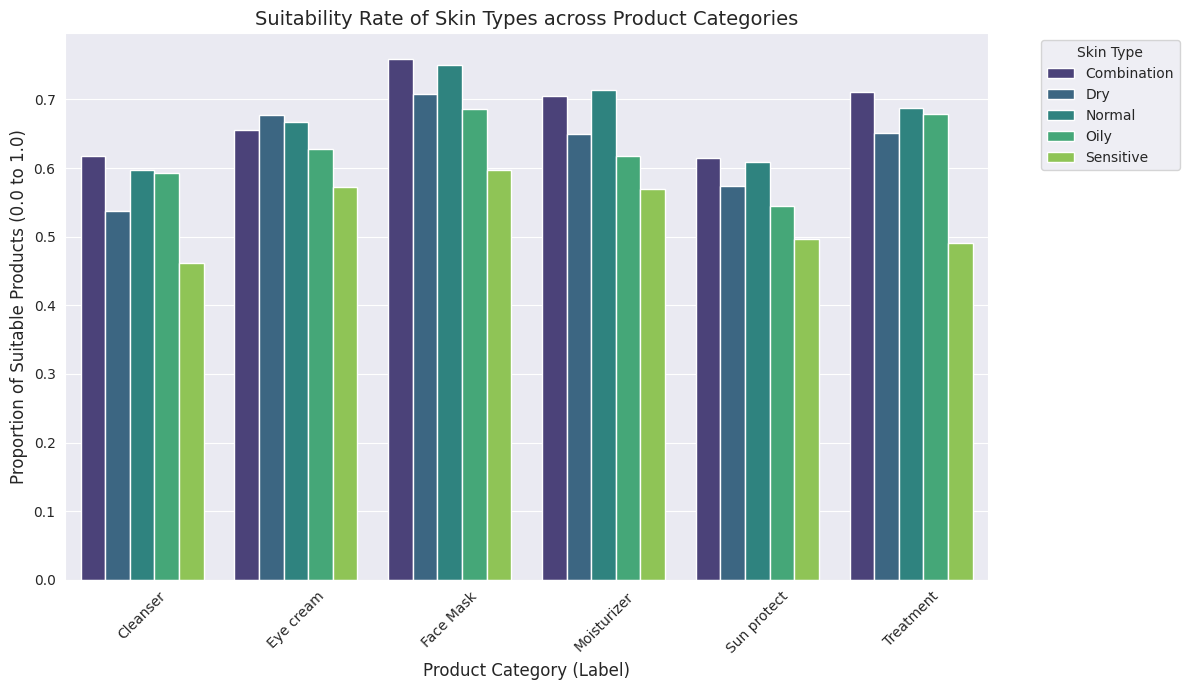

In [39]:
# Bivariate Analysis
# AI-generated code

# Calculate the proportion of products suitable (1) for each skin type by product Label (category)
category_suitability = df.groupby('Label')[SKIN].mean().reset_index()

# Melt the dataframe to a long format for plotting
melted_suitability = category_suitability.melt(id_vars='Label', var_name='Skin Type', value_name='Suitability Rate')

plt.figure(figsize=(12, 7))
sns.barplot(x='Label', y='Suitability Rate', hue='Skin Type', data=melted_suitability, palette='viridis')
plt.title('Suitability Rate of Skin Types across Product Categories', fontsize=14)
plt.xlabel('Product Category (Label)', fontsize=12)
plt.ylabel('Proportion of Suitable Products (0.0 to 1.0)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Skin Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Overall, face masks had the highest suitability rate across all skin types. Sensitive skin had the lowest suitability rates across all product categories compared to the other skin types.

#### Split data based on Holdout

In [ ]:
def choose_group_split(data, holdout_fraction, seed, attempts=100):
    """Search deterministic group splits for close label prevalence; no identical ingredient set crosses splits."""
    groups = data["formulation_group"].to_numpy()
    y = data[SKIN].to_numpy(dtype=float)
    target = y.mean(axis=0)
    best = None
    for k in range(attempts):
        splitter = GroupShuffleSplit(n_splits=1, test_size=holdout_fraction, random_state=seed+k)
        a, b = next(splitter.split(data, groups=groups))
        if not len(a) or not len(b):
            continue
        # Penalize large deviations in size and per-label prevalence.
        score = 2 * abs(len(b)/len(data)-holdout_fraction) + np.abs(y[b].mean(axis=0)-target).mean()
        if best is None or score < best[0]:
            best = (score, a, b)
    if best is None:
        raise ValueError("Could not create group-disjoint split")
    return data.iloc[best[1]].copy(), data.iloc[best[2]].copy()

train_val, test = choose_group_split(labeled, TEST_FRACTION, SEED)
train, val = choose_group_split(train_val, VALIDATION_FRACTION/(1-TEST_FRACTION), SEED+1000)
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(name, len(part), "label prevalence:", part[SKIN].mean().round(3).to_dict())
    if part[SKIN].nunique().min() < 2:
        print(f"WARNING: at least one target is constant in {name}; some metrics may be undefined")
assert not (set(train.formulation_group) & set(val.formulation_group))
assert not (set(train.formulation_group) & set(test.formulation_group))
assert not (set(val.formulation_group) & set(test.formulation_group))
assert len(train) + len(val) + len(test) == len(labeled)


train 623 label prevalence: {'Combination': 0.971, 'Dry': 0.904, 'Normal': 0.96, 'Oily': 0.889, 'Sensitive': 0.754}
validation 133 label prevalence: {'Combination': 0.97, 'Dry': 0.895, 'Normal': 0.962, 'Oily': 0.91, 'Sensitive': 0.767}
test 134 label prevalence: {'Combination': 0.97, 'Dry': 0.91, 'Normal': 0.963, 'Oily': 0.91, 'Sensitive': 0.769}


### Feature Engineering

In [ ]:
# X = ingredient presence + one-hot selected skin type.
# y = estimated 0..100 affinity (NOT ground-truth clinical compatibility).
# Scores use smoothed ingredient/tag co-occurrence and a neutral 50-point reference.
# For each ingredient, estimate tag prevalence for each skin type; the score is
# 50 + average of (prevalence - 0.5)*100, with shrinkage toward 0.5.
# This deliberately avoids presenting the globally high tag prevalence as near-100% compatibility.
from sklearn.model_selection import KFold

vectorizer = CountVectorizer(analyzer=lambda tokens: tokens, binary=True, min_df=MIN_DF, dtype=np.int8)
X_ing_train = vectorizer.fit_transform(train["tokens"]).tocsr()
X_ing_val = vectorizer.transform(val["tokens"]).tocsr()
X_ing_test = vectorizer.transform(test["tokens"]).tocsr()
features = vectorizer.get_feature_names_out().tolist()
if not features:
    raise ValueError("Vocabulary empty; lower MIN_DF or inspect ingredient parsing")

PRIOR_STRENGTH = 20.0

def fit_affinity(ingredient_matrix, tags):
    """Learn smoothed P(tag=1 | ingredient present) from training products only."""
    m = ingredient_matrix.astype(np.float64).tocsr()
    counts = np.asarray(m.sum(axis=0)).ravel()
    positives = np.asarray(m.T @ tags.astype(np.float64))
    # Fixed neutral prior: unknown evidence maps to 50 rather than artificial certainty.
    return (positives + 0.5 * PRIOR_STRENGTH) / (counts[:, None] + PRIOR_STRENGTH)

def score_affinity(ingredient_matrix, affinity):
    """One score per product and skin type; 50 for no recognized ingredients."""
    m = ingredient_matrix.astype(np.float64).tocsr()
    denom = np.asarray(m.sum(axis=1)).ravel()
    deviation = np.asarray(m @ (affinity - 0.5))
    scores = 50 + 100 * deviation / np.maximum(denom[:, None], 1)
    return np.clip(scores, 0, 100).astype(np.float32)

# Out-of-fold targets for training products: no product contributes to its own target.
# This is still a constructed heuristic, not measured truth.
train_tags = train[SKIN].to_numpy(dtype=np.int8)
train_scores = np.empty((len(train), len(SKIN)), dtype=np.float32)
train_groups = train["formulation_group"].to_numpy()
from sklearn.model_selection import GroupKFold
n_folds = min(5, len(np.unique(train_groups)))
if n_folds < 2:
    raise ValueError("Not enough distinct formulation groups for out-of-fold scoring")
for fit_idx, score_idx in GroupKFold(n_splits=n_folds).split(X_ing_train, groups=train_groups):
    fold_affinity = fit_affinity(X_ing_train[fit_idx], train_tags[fit_idx])
    train_scores[score_idx] = score_affinity(X_ing_train[score_idx], fold_affinity)

# Frozen mapping for validation, test, and future user inputs.
full_affinity = fit_affinity(X_ing_train, train_tags)
val_scores = score_affinity(X_ing_val, full_affinity)
test_scores = score_affinity(X_ing_test, full_affinity)

def expand_pairs(part, X_ingredients, scores):
    n, k = len(part), len(SKIN)
    repeated = X_ingredients[np.repeat(np.arange(n), k)]
    onehot = sparse.csr_matrix(np.tile(np.eye(k, dtype=np.int8), (n, 1)))
    X = sparse.hstack([repeated, onehot], format="csr", dtype=np.int8)
    y = scores.reshape(-1).astype(np.float32)
    manifest = pd.DataFrame({
        "source_row": np.repeat(part["source_row"].to_numpy(), k),
        "Brand": np.repeat(part["Brand"].to_numpy(), k),
        "Name": np.repeat(part["Name"].to_numpy(), k),
        "formulation_group": np.repeat(part["formulation_group"].to_numpy(), k),
        "skin_type": np.tile(SKIN, n),
        "original_binary_tag": part[SKIN].to_numpy(dtype=np.int8).reshape(-1),
        "target_score_percent": y,
    })
    assert X.shape == (n*k, len(features)+k)
    assert np.all((y >= 0) & (y <= 100))
    assert np.array_equal(np.asarray(X[:, -k:].sum(axis=1)).ravel(), np.ones(n*k))
    return X, y, manifest

X_train, y_train, train_pairs = expand_pairs(train, X_ing_train, train_scores)
X_val, y_val, val_pairs = expand_pairs(val, X_ing_val, val_scores)
X_test, y_test, test_pairs = expand_pairs(test, X_ing_test, test_scores)

report = {"raw_rows": int(raw_count), "cleaned_rows": int(len(df)),
          "labeled_products": int(len(labeled)),
          "unknown_all_zero_products": int(len(df)-len(labeled)),
          "ingredient_features": len(features), "skin_onehot_features": len(SKIN),
          "total_features": len(features)+len(SKIN),
          "split_products": {}, "split_pairs": {}, "score_summary": {},
          "empty_ingredient_product_rows": {}, "unseen_ingredient_fraction": {}}
for name, part, X_ing, X, y in [("train", train, X_ing_train, X_train, y_train),
                                 ("validation", val, X_ing_val, X_val, y_val),
                                 ("test", test, X_ing_test, X_test, y_test)]:
    report["split_products"][name] = len(part)
    report["split_pairs"][name] = len(y)
    report["score_summary"][name] = {"min": float(y.min()), "mean": float(y.mean()),
                                     "max": float(y.max()), "std": float(y.std())}
    report["empty_ingredient_product_rows"][name] = int(np.count_nonzero(np.asarray(X_ing.sum(axis=1)).ravel() == 0))
    all_tokens = [t for row in part["tokens"] for t in row]
    report["unseen_ingredient_fraction"][name] = round(sum(t not in vectorizer.vocabulary_ for t in all_tokens)/max(1,len(all_tokens)), 5)
    print(name, "products:", len(part), "pairs:", X.shape, "score mean:", round(float(y.mean()), 2))
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert all(y.ndim == 1 and np.isfinite(y).all() for y in [y_train, y_val, y_test])
assert set(train_pairs.source_row).isdisjoint(val_pairs.source_row)
assert set(train_pairs.source_row).isdisjoint(test_pairs.source_row)
assert set(val_pairs.source_row).isdisjoint(test_pairs.source_row)


train products: 623 pairs: (3115, 1296) score mean: 72.06
validation products: 133 pairs: (665, 1296) score mean: 74.69
test products: 134 pairs: (670, 1296) score mean: 75.2


Export Preprocessed Data

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
cols = ["source_row", "Label", "Brand", "Name", "Price", "Rank", "Rank_clean", "Ingredients_clean", "n_ing", *SKIN, "has_skin_label"]
df[cols].to_csv(OUT_DIR / "clean_cosmetics.csv", index=False)
for name, X, y, manifest in [("train", X_train, y_train, train_pairs),
                             ("val", X_val, y_val, val_pairs),
                             ("test", X_test, y_test, test_pairs)]:
    sparse.save_npz(OUT_DIR / f"X_{name}.npz", X)
    np.save(OUT_DIR / f"y_{name}.npy", y)
    manifest.to_csv(OUT_DIR / f"{name}_manifest.csv", index=False)
np.save(OUT_DIR / "ingredient_affinity.npy", full_affinity.astype(np.float32))
metadata = {"schema_version": 4, "task": "exploratory percentage-score regression",
            "skin_columns": SKIN, "vocabulary": features, "ingredient_feature_count": len(features),
            "feature_layout": "ingredient_binary_then_skin_onehot", "skin_onehot_order": SKIN,
            "aliases": ALIASES, "seed": SEED, "min_df": MIN_DF,
            "min_ingredients": MIN_INGREDIENTS, "test_fraction_requested": TEST_FRACTION,
            "validation_fraction_requested": VALIDATION_FRACTION,
            "target_definition": "0-100 statistical proxy from smoothed ingredient/skin-tag co-occurrence; NOT true compatibility percentage",
            "target_method": "50 + 100*mean(smoothed_P(tag=1|ingredient)-0.5); prior=0.5 strength=20; train out-of-fold by formulation group",
            "preprocessing": "parse_ingredients function in medical.ipynb; keep implementation versioned",
            "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit_learn": sklearn.__version__, "scipy": scipy.__version__}
(OUT_DIR / "vocabulary.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
(OUT_DIR / "quality_report.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved:", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n - ")


Saved:
 - X_test.npz
 - X_train.npz
 - X_val.npz
 - clean_cosmetics.csv
 - ingredient_affinity.npy
 - quality_report.json
 - test_manifest.csv
 - train_manifest.csv
 - val_manifest.csv
 - vocabulary.json
 - y_test.npy
 - y_train.npy
 - y_val.npy


## Inference: user inputs ingredients and one skin type

**Do not interpret output as a medically verified compatibility percentage.** It is a statistical proxy learned from noisy product tags. Unknown ingredients cannot be evaluated; zero recognized ingredients produce a neutral score of 50 and should trigger an insufficient-evidence warning.

The following reproduces the target heuristic directly (no regression model required):

```python
import json
import numpy as np
from scipy import sparse
from pathlib import Path
meta = json.loads(Path("prepared/vocabulary.json").read_text(encoding="utf-8"))
affinity = np.load("prepared/ingredient_affinity.npy")
lookup = {ingredient: i for i, ingredient in enumerate(meta["vocabulary"])}
skin = "Oily"  # user-selected
ingredients = parse_ingredients("Glycerin, Niacinamide, Salicylic Acid")
known = [lookup[t] for t in ingredients if t in lookup]
if skin not in meta["skin_columns"]:
    raise ValueError("Unsupported skin type")
if not known:
    print("Insufficient evidence: no recognized ingredients")
else:
    score = 50 + 100 * float(np.mean(affinity[known, meta["skin_columns"].index(skin)] - 0.5))
    print(f"Exploratory affinity score: {np.clip(score, 0, 100):.1f}/100")
```

If a regression model is trained, use `X_train.npz` / `y_train.npy` and evaluate on validation/test. Regression can only reproduce the **constructed proxy**, not validate real-world suitability. Split by product/formulation, never by expanded pair.
